<a href="https://colab.research.google.com/github/dramaticforyouenjoy-sudo/RIT-Trading-Competition-2026/blob/main/Performance_Returns_For_SMA_Cross.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Input the ticker you want: 
NoneMU


/tmp/ipykernel_12826/1079359474.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(tickername,start="2025-01-01",end="2026-11-8",progress=False,multi_level_index=False)


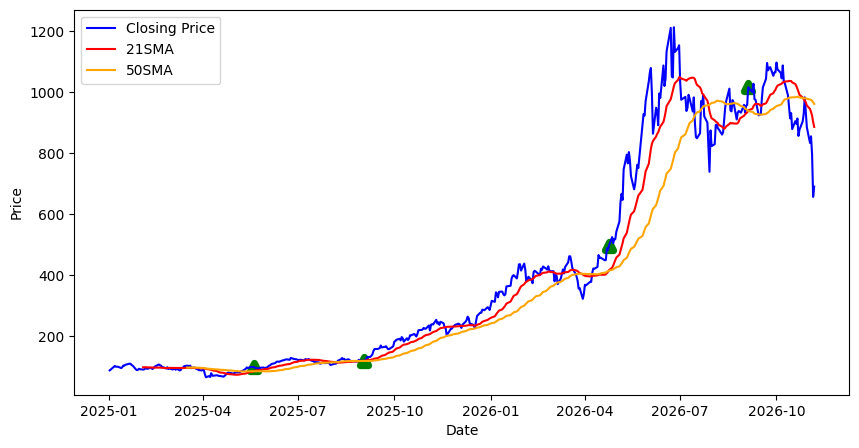

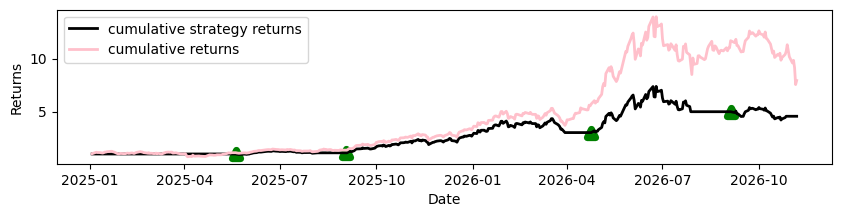

                 Close        High         Low        Open    Volume  \
Date                                                                   
2026-01-23  399.357880  412.128537  390.454389  396.869709  35404200   
2026-01-26  388.805603  397.709094  384.019096  395.210921  29193900   
2026-01-27  409.940155  416.145638  399.307947  404.314265  36212100   
2026-01-28  434.961884  438.619212  416.695244  422.131271  42725700   
2026-01-29  435.471497  444.384960  417.394722  439.048867  42675700   
...                ...         ...         ...         ...       ...   
2026-11-02  833.590027  892.080017  829.239990  890.539978  29902100   
2026-11-03  855.099976  871.489990  845.250000  859.929993  21286500   
2026-11-04  795.229980  853.340027  782.000000  823.000000  35906100   
2026-11-05  656.390015  761.809998  650.000000  752.690002  77872700   
2026-11-06  690.000000  724.799988  676.000000  708.349976  44887900   

                 21SMA       50SMA  signal   returns  strategy_

In [32]:
from matplotlib.typing import MarkerType
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
!pip install pandas_ta_classic -q
import pandas_ta_classic as ta

tickername = input(print("Input the ticker you want: "))

df = yf.download(tickername,start="2025-01-01",end="2026-11-8",progress=False,multi_level_index=False)

df['21SMA'] = df.ta.sma(length=21,append=False)
df['50SMA'] = df.ta.sma(length=50,append=False)

df['signal'] = 0

df.loc[df['21SMA'] > df['50SMA'], 'signal'] = 1
# df.loc[df['21SMA'] < df['50SMA'], 'signal'] = -1

df['returns'] = df['Close'].pct_change()
df['strategy_returns'] = df['signal'].shift(1)*df['returns']

df['cumulative_returns'] = (1 + df['returns']).cumprod()
df['cumulative_strategy_returns'] = (1+df['strategy_returns']).cumprod()

buy_points = df[df['signal'].diff() == 1]
# sell_points = df[df['signal'].diff() == -2]

strategy_equity = df['Close'].iloc[0] * df['cumulative_strategy_returns'].dropna()
strategy_sharpe = ta.sharpe_ratio(strategy_equity)

winning_trades = df[df['strategy_returns'] > 0]
losing_trades = df[df['strategy_returns'] < 0]

win_rate = len(winning_trades) / (len(winning_trades) + len(losing_trades)) * 100

avg_win = winning_trades['strategy_returns'].mean() * 100

plt.figure(figsize=(10,5))
plt.plot(df.index,df['Close'],label='Closing Price',color='blue')
plt.plot(df.index,df['21SMA'],label='21SMA',color='red')
plt.plot(df.index,df['50SMA'],label='50SMA',color='orange')
plt.scatter(buy_points.index,buy_points['Close'],marker='^',color='green',linewidths=5)
# plt.scatter(sell_points.index,sell_points['Close'],marker='v',color='red',linewidths=5)

plt.xlabel('Date', fontsize=10)
plt.ylabel('Price',fontsize=10)
plt.legend()
plt.show()


plt.figure(figsize=(10,2))
plt.plot(df.index,df['cumulative_strategy_returns'],label='cumulative strategy returns',color='black',linewidth=2)
plt.plot(df.index,df['cumulative_returns'],label='cumulative returns',color='pink',linewidth=2)
plt.scatter(buy_points.index,buy_points['cumulative_strategy_returns'],marker='^',color='green',linewidths=5)
# plt.scatter(sell_points.index,sell_points['cumulative_strategy_returns'],marker='v',color='red',linewidths=5)
plt.xlabel('Date',fontsize=10)
plt.ylabel('Returns',fontsize=10)
plt.legend()
plt.show()

print(df.tail(200))
print(f"Strategy Sharpe Ratio: {strategy_sharpe:.2f}")
print(f"Win Rate: {win_rate:.2f}")
print(f"Avg Win Rate: {avg_win:.2f}")
